# Regional cleanup arms by season

`ks_regional_arms.ipynb` tests whole 10-year windows (120 months). Aerosol effects are seasonal — monsoon
precipitation in JJA, winter haze and shortwave over East Asia in DJF — so here every window is split into
DJF, MAM, JJA and SON and each season is tested on its own: 3 months × 10 years = 30 months per side, blocks of one
season-year (3 months), DJF taken as Dec(y−1)–Jan(y)–Feb(y) with the window extended by one December. Same arms,
anchors, pairs and 1° pipeline as the full-window notebook; variables `tas`, `pr`, `tasmax`, `tasmin`, `dtr`.

With 30 months per side the per-cell test needs roughly twice the shift the 120-month test needs, so three more
quantities are computed per season from the same regridded windows: the **box-mean seasonal difference** per pair,
a **pooled-ensemble test** inside the emission box (all members concatenated on each side, blocks unchanged) with
its own null (the anchor's members split in halves), and the in-box FDR against a **seasonal same-forcing null**
(`null_1deg_seasonal_{var}.nc`, 45 CanESM5-1 pairs per season). Caches: `diagnostics/regional_arms_seasonal/{anchor}_{arm}_{var}_{model}.nc`
with dims `season × pair × lat × lon` plus `d_box(season, pair)`, `p_pooled(season, lat, lon)`, `p_pooled_null`.

In [1]:
import os, re, warnings
os.environ.setdefault('ESMFMKFILE', '/burg-archive/home/mck2199/summer/.esmf/lib/esmf.mk')
import numpy as np
import pandas as pd
import xarray as xr

import sys
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/code')
sys.path.insert(0, '/burg-archive/home/mck2199/summer/bcd_me/path_independence')
from funcs_support import get_params
import ks_tools as kt

dir_list = get_params()
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

RAMIP   = dir_list['raw'] + 'ramip/'
SCEN    = dir_list['raw'] + 'scenariomip/'
PRODUCT = dir_list['aux'] + 'gwl_timeseries.zarr'
GWL_DIR = dir_list['aux'] + 'diagnostics/ramip_gwl/'
KS_DIR  = dir_list['aux'] + 'diagnostics/regional_arms_seasonal/'
out_dir = dir_list['aux'] + '../figures/e3_regional_arms/'
os.makedirs(out_dir, exist_ok=True)
os.makedirs(KS_DIR, exist_ok=True)

GWL, ALPHA, FDR = 2.0, 0.05, 0.2
VARS = ['tas', 'pr', 'tasmax', 'tasmin', 'dtr']   # gdp left out: for a KS test it is the tas test
SEASONS = list(kt.SEASONS)                          # DJF = Dec(y-1)-Jan(y)-Feb(y); 3-month blocks, 30 months per side
ARMS = {'eas': 'ssp370-EAS126aer', 'sas': 'ssp370-SAS126aer', 'afr': 'ssp370-AFR126aer', 'nae': 'ssp370-NAE126aer',
        'asia': 'ssp370-ASIA126aer', 'safca': 'ssp370-SAF126ca', 'sasca': 'ssp370-SAS126ca'}

# anchor 1: own ssp370 parent (RAMIP)
PARENT = {m: 'ssp370' for m in ['CanESM5-1', 'CNRM-ESM2-1', 'EC-Earth3-AerChem', 'GISS-E2-1-G',
                                'MIROC6', 'MRI-ESM2-0', 'NorESM2-LM', 'UKESM1-0-LL']}
PARENT['CESM2'] = 'ssp370-LE'
# anchor 2: ssp585 (ScenarioMIP model id -> RAMIP model id); MIROC6 invalid across archives
EXCLUDE_585 = ['MIROC6']
MODEL_MAP = {'CanESM5': 'CanESM5-1', 'CESM2': 'CESM2', 'CNRM-ESM2-1': 'CNRM-ESM2-1',
             'GISS-E2-1-G': 'GISS-E2-1-G', 'MRI-ESM2-0': 'MRI-ESM2-0', 'UKESM1-0-LL': 'UKESM1-0-LL'}

_gmst = xr.open_zarr(PRODUCT, group='gmst')
_gwl  = xr.open_zarr(PRODUCT, group='gwl')
win_df = pd.read_csv(f'{GWL_DIR}gwl{GWL}_windows.csv')


def gwl_ends(mod, exp):
    ids = _gmst.run_id.sel(model=mod, exp=exp).values
    we  = _gwl.window_end.sel(model=mod, exp=exp, gwl=GWL).values
    return {str(r): int(e) for r, e in zip(ids, we) if r and np.isfinite(e)}


def variant(run):
    return re.search(r'(p\d+f\d+)$', run).group(1)


def parent_pairs(mod, arm_exp):
    """(run, parent_end, run, arm_end): the arm against its own parent run, as ks_gwl_1deg does
    for the East-Asia arm. Parent windows come from the audited gwl2.0_windows.csv."""
    ends = gwl_ends(mod, arm_exp)
    rows = win_df[(win_df.model == mod) & win_df.usable]
    return [(r.run, int(r.anchor_end), r.run, ends[r.run]) for _, r in rows.iterrows() if r.run in ends]


def variant_pairs(mod_a, exp_a, mod_b, exp_b):
    """(run_a, end_a, run_b, end_b) formed within a p<n>f<n> variant, by sorted index"""
    a, b = gwl_ends(mod_a, exp_a), gwl_ends(mod_b, exp_b)
    by = lambda d: {v: sorted(r for r in d if variant(r) == v) for v in {variant(r) for r in d}}
    va, vb = by(a), by(b)
    out = []
    for v in sorted(set(va) & set(vb)):
        for ra, rb in zip(va[v], vb[v]):
            assert variant(ra) == variant(rb)
            out.append((ra, a[ra], rb, b[rb]))
    return out


# Optional subset for job-array runs: ARM=sas|afr|..., ANCHOR=370|585 (unset = everything).
# Caches are per (anchor, arm, var, model), so parallel subsets never write the same file.
ONLY_ARM, ONLY_ANCHOR = os.environ.get('ARM'), os.environ.get('ANCHOR')
if ONLY_ARM:
    ARMS = {ONLY_ARM: ARMS[ONLY_ARM]}

# JOBS[(anchor, arm, model)] = (anchor_root, anchor_model, anchor_exp, arm_model, pairs)
JOBS = {}
for arm, exp in ARMS.items():
    for m in PARENT:
        prs = parent_pairs(m, exp)
        if prs:
            JOBS[('370', arm, m)] = (RAMIP, m, PARENT[m], m, prs)
    for ms, mr in MODEL_MAP.items():
        prs = variant_pairs(ms, 'ssp585', mr, exp)
        if prs:
            JOBS[('585', arm, ms)] = (SCEN, ms, 'ssp585', mr, prs)
if ONLY_ANCHOR:
    JOBS = {k: v for k, v in JOBS.items() if k[0] == ONLY_ANCHOR}
print('subset:', ONLY_ARM or 'all arms', '/', ONLY_ANCHOR or 'both anchors')

summary = pd.DataFrame([{'anchor': k[0], 'arm': k[1], 'model': k[2], 'n_pairs': len(v[4]),
                         'mean_lead_yr': np.mean([ea - eb for _, ea, _, eb in v[4]])}
                        for k, v in JOBS.items()])
print(summary.pivot_table(index=['anchor', 'arm'], columns='model', values='n_pairs').fillna(0).astype(int).to_string())
print('total pair-tests:', int(summary.n_pairs.sum()) * len(VARS))
print('\nmean GWL-2.0 lead of the anchor over the arm (yr):')
print(summary.groupby(['anchor', 'arm']).mean_lead_yr.mean().round(1).to_string())

# RAMIP emission boxes (Wilcox et al. 2023): (lat_lo, lat_hi), (lon_lo, lon_hi), degrees east in -180..180
BOXES = {
    'eas':   [((20, 53), (95, 133))],
    'sas':   [((5, 35), (65, 95))],
    'afr':   [((-35, 35), (-20, 60))],
    'nae':   [((35, 70), (-20, 45)), ((25, 70), (-150, -45))],
    'asia':  [((20, 53), (95, 133)), ((5, 35), (65, 95))],
    'safca': [((-35, 12), (-20, 50))],
    'sasca': [((5, 35), (65, 95))],
}


def box_mask(lat, lon, boxes):
    lon = np.asarray(lon)
    LA, LO = np.meshgrid(lat, np.where(lon > 180, lon - 360, lon), indexing='ij')
    m = np.zeros(LA.shape, bool)
    for (a, b), (c, d) in boxes:
        m |= (LA >= a) & (LA <= b) & (LO >= c) & (LO <= d)
    return m


LAND1 = kt.land_mask(kt.GRID_OUT['lat'], kt.GRID_OUT['lon'])
W1 = (np.cos(np.deg2rad(kt.GRID_OUT['lat']))[:, None] * np.ones(kt.NLON)).ravel()
BOX1 = {arm: (box_mask(kt.GRID_OUT['lat'], kt.GRID_OUT['lon'], b) & LAND1).ravel() for arm, b in BOXES.items()}

subset: all arms / both anchors
model         CESM2  CNRM-ESM2-1  CanESM5  CanESM5-1  EC-Earth3-AerChem  GISS-E2-1-G  MIROC6  MRI-ESM2-0  UKESM1-0-LL
anchor arm                                                                                                           
370    afr       10            1        0         10                  6           10      10           1           10
       asia       0            0        0          0                  0           10       6           0            0
       eas       10            1        0         10                  6           10      10          10           10
       nae       10            1        0         10                  5           10      10          10           10
       safca      0            0        0          0                  0            9       1           0            0
       sas       10            0        0         10                  6           10      10           7            9
       sasca      0     

## KS per season on the common 1° grid, with box-mean differences and the pooled in-box test

In [2]:
def seasonal_sides(fa, fb, var, ea, eb):
    """{season: (A, B)} as (cells, 30) arrays on the 1deg grid; one load and regrid per side.
    None if a source is missing or any season is short (a window starting at the record's first year has no
    preceding December for DJF)."""
    out = {}
    va = kt.window_1deg(fa, var, ea, kt.WIN, extra_dec=True)
    vb = kt.window_1deg(fb, var, eb, kt.WIN, extra_dec=True)
    if va is None or vb is None:
        return None
    for s in SEASONS:
        A, B = kt.season_values(va, s), kt.season_values(vb, s)
        if A is None or B is None:
            return None
        out[s] = (A, B)
    return out


def box_map(values, box):
    m = np.full(kt.NLAT * kt.NLON, np.nan, 'float32'); m[box] = values
    return m.reshape(kt.NLAT, kt.NLON)


results = {}
for (anc, arm, mod), (aroot, amod, aexp, bmod, prs) in JOBS.items():
    box = BOX1[arm]; wbox = W1[box]
    for var in VARS:
        cache_fn = f'{KS_DIR}{anc}_{arm}_{var}_{mod}.nc'
        if os.path.exists(cache_fn):
            results[(anc, arm, var, mod)] = xr.open_dataset(cache_fn).load()
            continue
        src = kt.SRC_VAR.get(var, var)
        afns = kt.member_files(aroot, amod, aexp, src)
        bfns = kt.member_files(RAMIP, bmod, ARMS[arm], src)
        if not afns or not bfns:
            print(f'{anc} {arm} {var} {mod}: no {src} files on one side, skipped'); continue
        P = {s: [] for s in SEASONS}; D = {s: [] for s in SEASONS}
        poolA = {s: [] for s in SEASONS}; poolB = {s: [] for s in SEASONS}; used = []
        for ra, ea, rb, eb in prs:
            if ra not in afns or rb not in bfns:
                print(f'  {anc} {arm} {var} {mod} {ra}/{rb}: no file, skipped'); continue
            sides = seasonal_sides(afns[ra], bfns[rb], var, ea, eb)
            if sides is None:
                print(f'  {anc} {arm} {var} {mod} {ra}/{rb}: short window, skipped'); continue
            for s, (A, B) in sides.items():
                P[s].append(kt.block_perm_map(A, B, 3).reshape(kt.NLAT, kt.NLON))
                mA, mB = A[box].mean(1), B[box].mean(1)                 # seasonal means per box cell
                d = np.average(mB - mA, weights=wbox)                   # arm minus anchor, box mean
                D[s].append(100 * d / np.average(mA, weights=wbox) if var == 'pr' else d)
                poolA[s].append(A[box]); poolB[s].append(B[box])
            used.append(f'{ra}|{rb}')
        if not used:
            print(f'{anc} {arm} {var} {mod}: nothing usable'); continue
        pooled = np.full((len(SEASONS), kt.NLAT, kt.NLON), np.nan, 'float32'); pnull = pooled.copy()
        for k, s in enumerate(SEASONS):
            pooled[k] = box_map(kt.block_perm_map(np.concatenate(poolA[s], 1), np.concatenate(poolB[s], 1), 3), box)
            h = len(poolA[s]) // 2
            if h >= 1:                                                  # anchor members split in two halves
                pnull[k] = box_map(kt.block_perm_map(np.concatenate(poolA[s][:h], 1),
                                                     np.concatenate(poolA[s][h:2 * h], 1), 3), box)
        ds = xr.Dataset({'p_blockperm': (('season', 'pair', 'lat', 'lon'),
                                         np.stack([np.stack(P[s]) for s in SEASONS]).astype('float32')),
                         'd_box': (('season', 'pair'), np.array([D[s] for s in SEASONS])),
                         'p_pooled': (('season', 'lat', 'lon'), pooled),
                         'p_pooled_null': (('season', 'lat', 'lon'), pnull)},
                        coords={'season': SEASONS, 'pair': used, 'lat': kt.GRID_OUT['lat'], 'lon': kt.GRID_OUT['lon']})
        ds.attrs.update(gwl=GWL, variable=var, anchor_exp=aexp, arm_exp=ARMS[arm], anchor_model=amod, arm_model=bmod,
                        pairing='same run id' if anc == '370' else 'within p<n>f<n> variant, sorted index',
                        blocks='3 months (one season-year), 30 months per side; DJF = Dec(y-1)-Jan(y)-Feb(y)',
                        d_box=('box-mean seasonal difference arm - anchor, land cells inside the emission box; '
                               'K, or % of the anchor mean for pr'),
                        p_pooled=f'all {len(used)} pairs concatenated on each side, cells inside the box only',
                        p_pooled_null='anchor members split in two halves, same cells',
                        regrid=f"xESMF {kt.METHOD.get(var, 'bilinear')}, 1deg, transform-before-regrid")
        ds.to_netcdf(cache_fn)
        results[(anc, arm, var, mod)] = ds
        print(f'{anc} {arm} {var} {mod}: {len(used)} pairs x 4 seasons -> {os.path.basename(cache_fn)}', flush=True)
print(len(results), 'seasonal map sets ready')

  585 eas tas CanESM5 r1i1p1f1/r10i1p1f1: short window, skipped


  585 eas tas CanESM5 r2i1p1f1/r1i1p1f1: short window, skipped


  585 eas tas CanESM5 r3i1p1f1/r2i1p1f1: short window, skipped


  585 eas tas CanESM5 r4i1p1f1/r3i1p1f1: short window, skipped


  585 eas tas CanESM5 r5i1p1f1/r4i1p1f1: short window, skipped
585 eas tas CanESM5: nothing usable


...

  585 nae dtr CanESM5 r2i1p1f1/r1i1p1f1: short window, skipped


  585 nae dtr CanESM5 r3i1p1f1/r2i1p1f1: short window, skipped


  585 nae dtr CanESM5 r4i1p1f1/r3i1p1f1: short window, skipped


  585 nae dtr CanESM5 r5i1p1f1/r4i1p1f1: short window, skipped
585 nae dtr CanESM5: nothing usable


305 seasonal map sets ready


## Summaries per season

Per anchor × arm × variable × season and model: global land fraction (raw p<0.05 and Wilks FDR), the same inside the
emission box against the seasonal same-forcing null, the box-mean seasonal difference, and the pooled in-box test
(fraction of box cells with p<0.05 and in-box FDR) against its split-halves null. Multi-model means in
`seasonal_summary.csv`, per model in `seasonal_by_model.csv` (MIROC6 excluded vs ssp585).

In [3]:
if ONLY_ARM or ONLY_ANCHOR:
    print('subset run: tables and figures are produced by the FINAL pass')
else:
    NULL = {}
    for var in VARS:
        nd = xr.open_dataset(f'{KS_DIR}null_1deg_seasonal_{var}.nc').load()
        for arm, box in BOX1.items():
            for s in SEASONS:
                p = nd.p_blockperm.sel(season=s)
                pb = p.where(xr.DataArray(box.reshape(kt.NLAT, kt.NLON), coords={'lat': p.lat, 'lon': p.lon}))
                NULL[(arm, var, s)] = {'null_in_box': float((p < ALPHA).values[:, box.reshape(kt.NLAT, kt.NLON)].mean()),
                                       'null_fdr_in_box': float((kt.sig_fdr(pb, FDR) == 1).sum(('lat', 'lon')).mean('pair')) / box.sum()}

    def season_stats(ds, arm, s):
        p = ds.p_blockperm.sel(season=s); box2 = BOX1[arm].reshape(kt.NLAT, kt.NLON)
        rej = (p < ALPHA).values
        pb = p.where(xr.DataArray(box2, coords={'lat': p.lat, 'lon': p.lon}))
        pp = ds.p_pooled.sel(season=s); pn = ds.p_pooled_null.sel(season=s)
        fdr_pool = float((kt.sig_fdr(pp.expand_dims('pair'), FDR) == 1).sum()) / box2.sum()
        return {'raw': rej[:, LAND1].mean(), 'fdr': kt.fdr_land_fraction(ds.sel(season=s), 'pair', FDR),
                'in_box': rej[:, box2].mean(), 'outside': rej[:, LAND1 & ~box2].mean(),
                'fdr_in_box': float((kt.sig_fdr(pb, FDR) == 1).sum(('lat', 'lon')).mean('pair')) / box2.sum(),
                'd_box': float(ds.d_box.sel(season=s).mean()), 'd_box_sd': float(ds.d_box.sel(season=s).std()),
                'pooled_in_box': float((pp < ALPHA).values[box2].mean()), 'pooled_fdr_in_box': fdr_pool,
                'pooled_null_in_box': float(np.nanmean((pn < ALPHA).values[box2])) if not np.isnan(pn.values[box2]).all() else np.nan}

    rows = []
    for (anc, arm, var, mod), ds in results.items():
        if anc == '585' and mod in EXCLUDE_585:
            continue
        for s in SEASONS:
            rows.append({'anchor': anc, 'arm': arm, 'var': var, 'season': s, 'model': mod, 'n_pairs': ds.sizes['pair'],
                         **season_stats(ds, arm, s), **NULL[(arm, var, s)]})
    bym = pd.DataFrame(rows)
    bym.to_csv(f'{KS_DIR}seasonal_by_model.csv', index=False)
    summ = (bym.groupby(['arm', 'anchor', 'var', 'season'])
               .agg(models=('model', 'nunique'), pairs=('n_pairs', 'sum'), raw=('raw', 'mean'), fdr=('fdr', 'mean'),
                    in_box=('in_box', 'mean'), outside=('outside', 'mean'), fdr_in_box=('fdr_in_box', 'mean'),
                    models_fdr_pos=('fdr_in_box', lambda x: int((x > 0).sum())), d_box=('d_box', 'mean'), d_box_sd=('d_box', 'std'),
                    pooled_in_box=('pooled_in_box', 'mean'), pooled_fdr_in_box=('pooled_fdr_in_box', 'mean'),
                    pooled_null_in_box=('pooled_null_in_box', 'mean'), null_in_box=('null_in_box', 'first'),
                    null_fdr_in_box=('null_fdr_in_box', 'first'))
               .reset_index())
    summ.to_csv(f'{KS_DIR}seasonal_summary.csv', index=False)
    pd.set_option('display.width', 250)
    print('seasonal same-forcing null (CanESM5-1, 1deg), global land fraction by season:')
    for var in VARS:
        nd = xr.open_dataset(f'{KS_DIR}null_1deg_seasonal_{var}.nc')
        print(f'  {var}:', {s: round(kt.land_fraction(nd.sel(season=s), 'pair'), 3) for s in SEASONS})
    print('\nvs own ssp370 parent, multi-model means (in-box FDR vs its null; pooled in-box rejection vs its null):')
    cols = ['arm', 'var', 'season', 'models', 'pairs', 'raw', 'fdr', 'in_box', 'outside', 'fdr_in_box', 'null_fdr_in_box',
            'models_fdr_pos', 'd_box', 'd_box_sd', 'pooled_in_box', 'pooled_null_in_box', 'pooled_fdr_in_box']
    print(summ[summ.anchor == '370'][cols].round(3).to_string(index=False))
    print('\nvs ssp585 (MIROC6 excluded):')
    print(summ[summ.anchor == '585'][cols].round(3).to_string(index=False))

seasonal same-forcing null (CanESM5-1, 1deg), global land fraction by season:
  tas: {'DJF': 0.038, 'MAM': 0.042, 'JJA': 0.032, 'SON': 0.039}
  pr: {'DJF': 0.034, 'MAM': 0.042, 'JJA': 0.038, 'SON': 0.036}
  tasmax: {'DJF': 0.043, 'MAM': 0.046, 'JJA': 0.036, 'SON': 0.039}
  tasmin: {'DJF': 0.038, 'MAM': 0.041, 'JJA': 0.029, 'SON': 0.037}
  dtr: {'DJF': 0.037, 'MAM': 0.046, 'JJA': 0.051, 'SON': 0.035}

vs own ssp370 parent, multi-model means (in-box FDR vs its null; pooled in-box rejection vs its null):
  arm    var season  models  pairs   raw   fdr  in_box  outside  fdr_in_box  null_fdr_in_box  models_fdr_pos  d_box  d_box_sd  pooled_in_box  pooled_null_in_box  pooled_fdr_in_box
  afr    dtr    DJF       8     56 0.037 0.000   0.043    0.037       0.000            0.000               1 -0.024     0.068          0.052               0.041              0.003
  afr    dtr    JJA       8     56 0.046 0.000   0.043    0.046       0.000            0.000               2  0.006     0.041        

  arm    var season  models  pairs   raw   fdr  in_box  outside  fdr_in_box  null_fdr_in_box  models_fdr_pos  d_box  d_box_sd  pooled_in_box  pooled_null_in_box  pooled_fdr_in_box
  afr    dtr    DJF       5     15 0.051 0.001   0.068    0.049       0.020            0.000               3  0.089     0.057          0.104               0.021              0.060
  afr    dtr    JJA       5     15 0.060 0.000   0.115    0.051       0.053            0.000               4  0.116     0.054          0.190               0.032              0.166
  afr    dtr    MAM       5     15 0.048 0.000   0.078    0.044       0.020            0.001               3  0.047     0.081          0.128               0.034              0.085
  afr    dtr    SON       5     15 0.052 0.000   0.080    0.048       0.019            0.000               4  0.026     0.060          0.130               0.044              0.093
  afr     pr    DJF       5     15 0.044 0.000   0.035    0.045       0.000            0.000        

## Figures

1. `ks_regional_arms_seasonal_inbox.png` — in-box FDR fraction by season for every arm (rows: variables, columns: anchors),
   dashed = seasonal same-forcing null for that box.
2. `ks_regional_arms_seasonal_effect.png` — box-mean seasonal difference, arm − anchor (K, or % for `pr`), bars = multi-model
   mean, dots = models.
3. `ks_regional_arms_seasonal_pooled.png` — pooled in-box test: fraction of box cells rejecting, bars vs the split-halves null.
4. `ks_regional_arms_seasonal_maps_{var}.png` — regional maps of the pooled test around each box, one column per season
   (vs ssp370, multi-model mean of the per-cell rejection indicator).

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e3_regional_arms/ks_regional_arms_seasonal_inbox.png


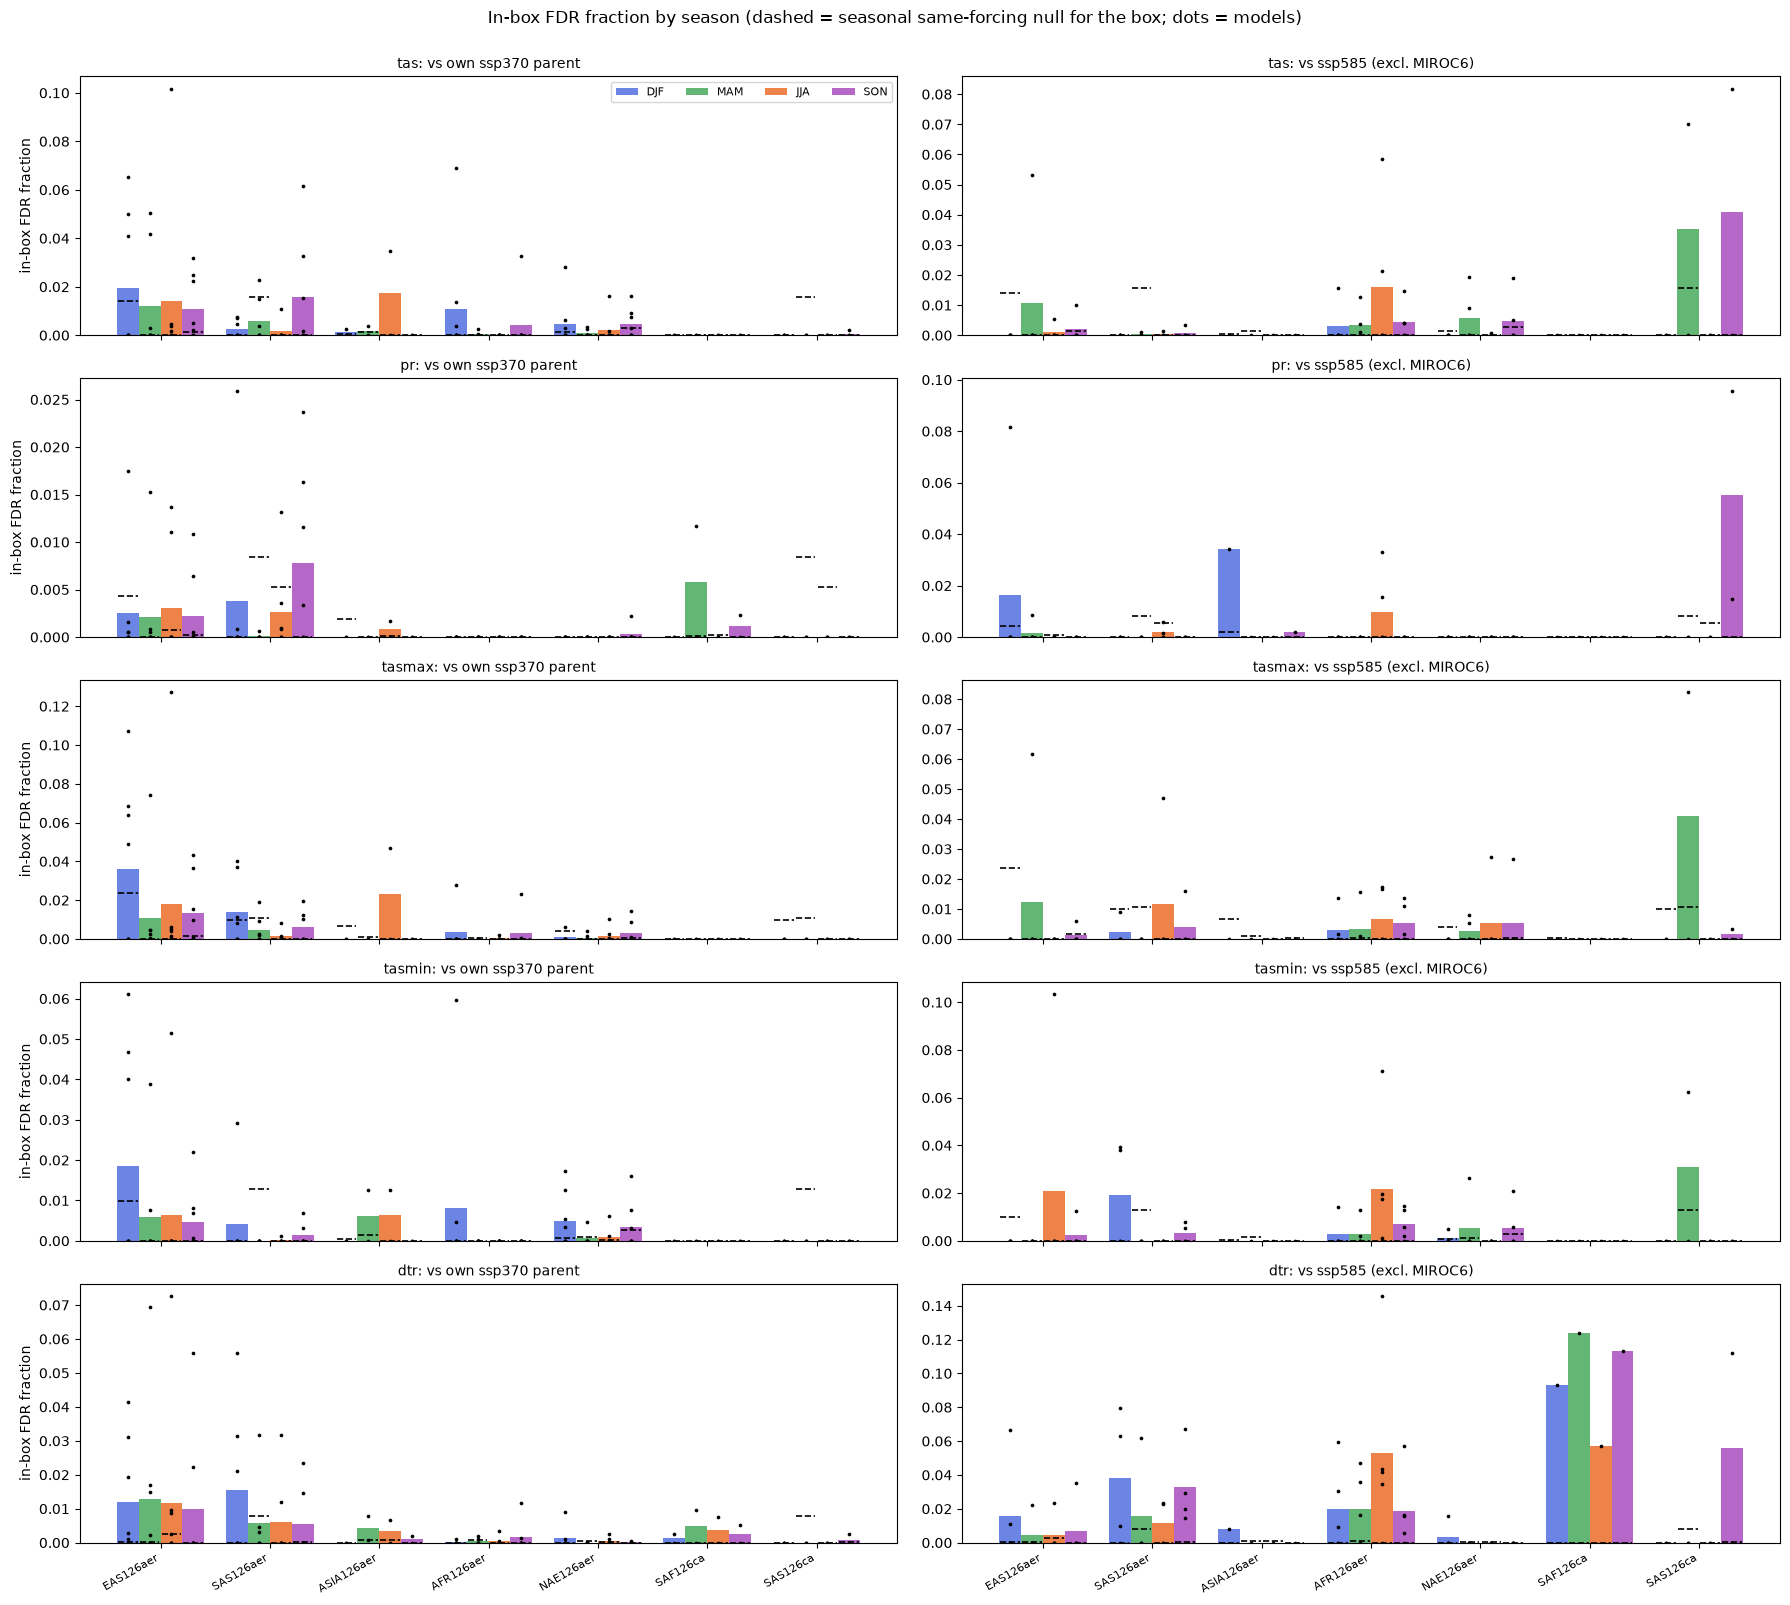

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e3_regional_arms/ks_regional_arms_seasonal_effect.png


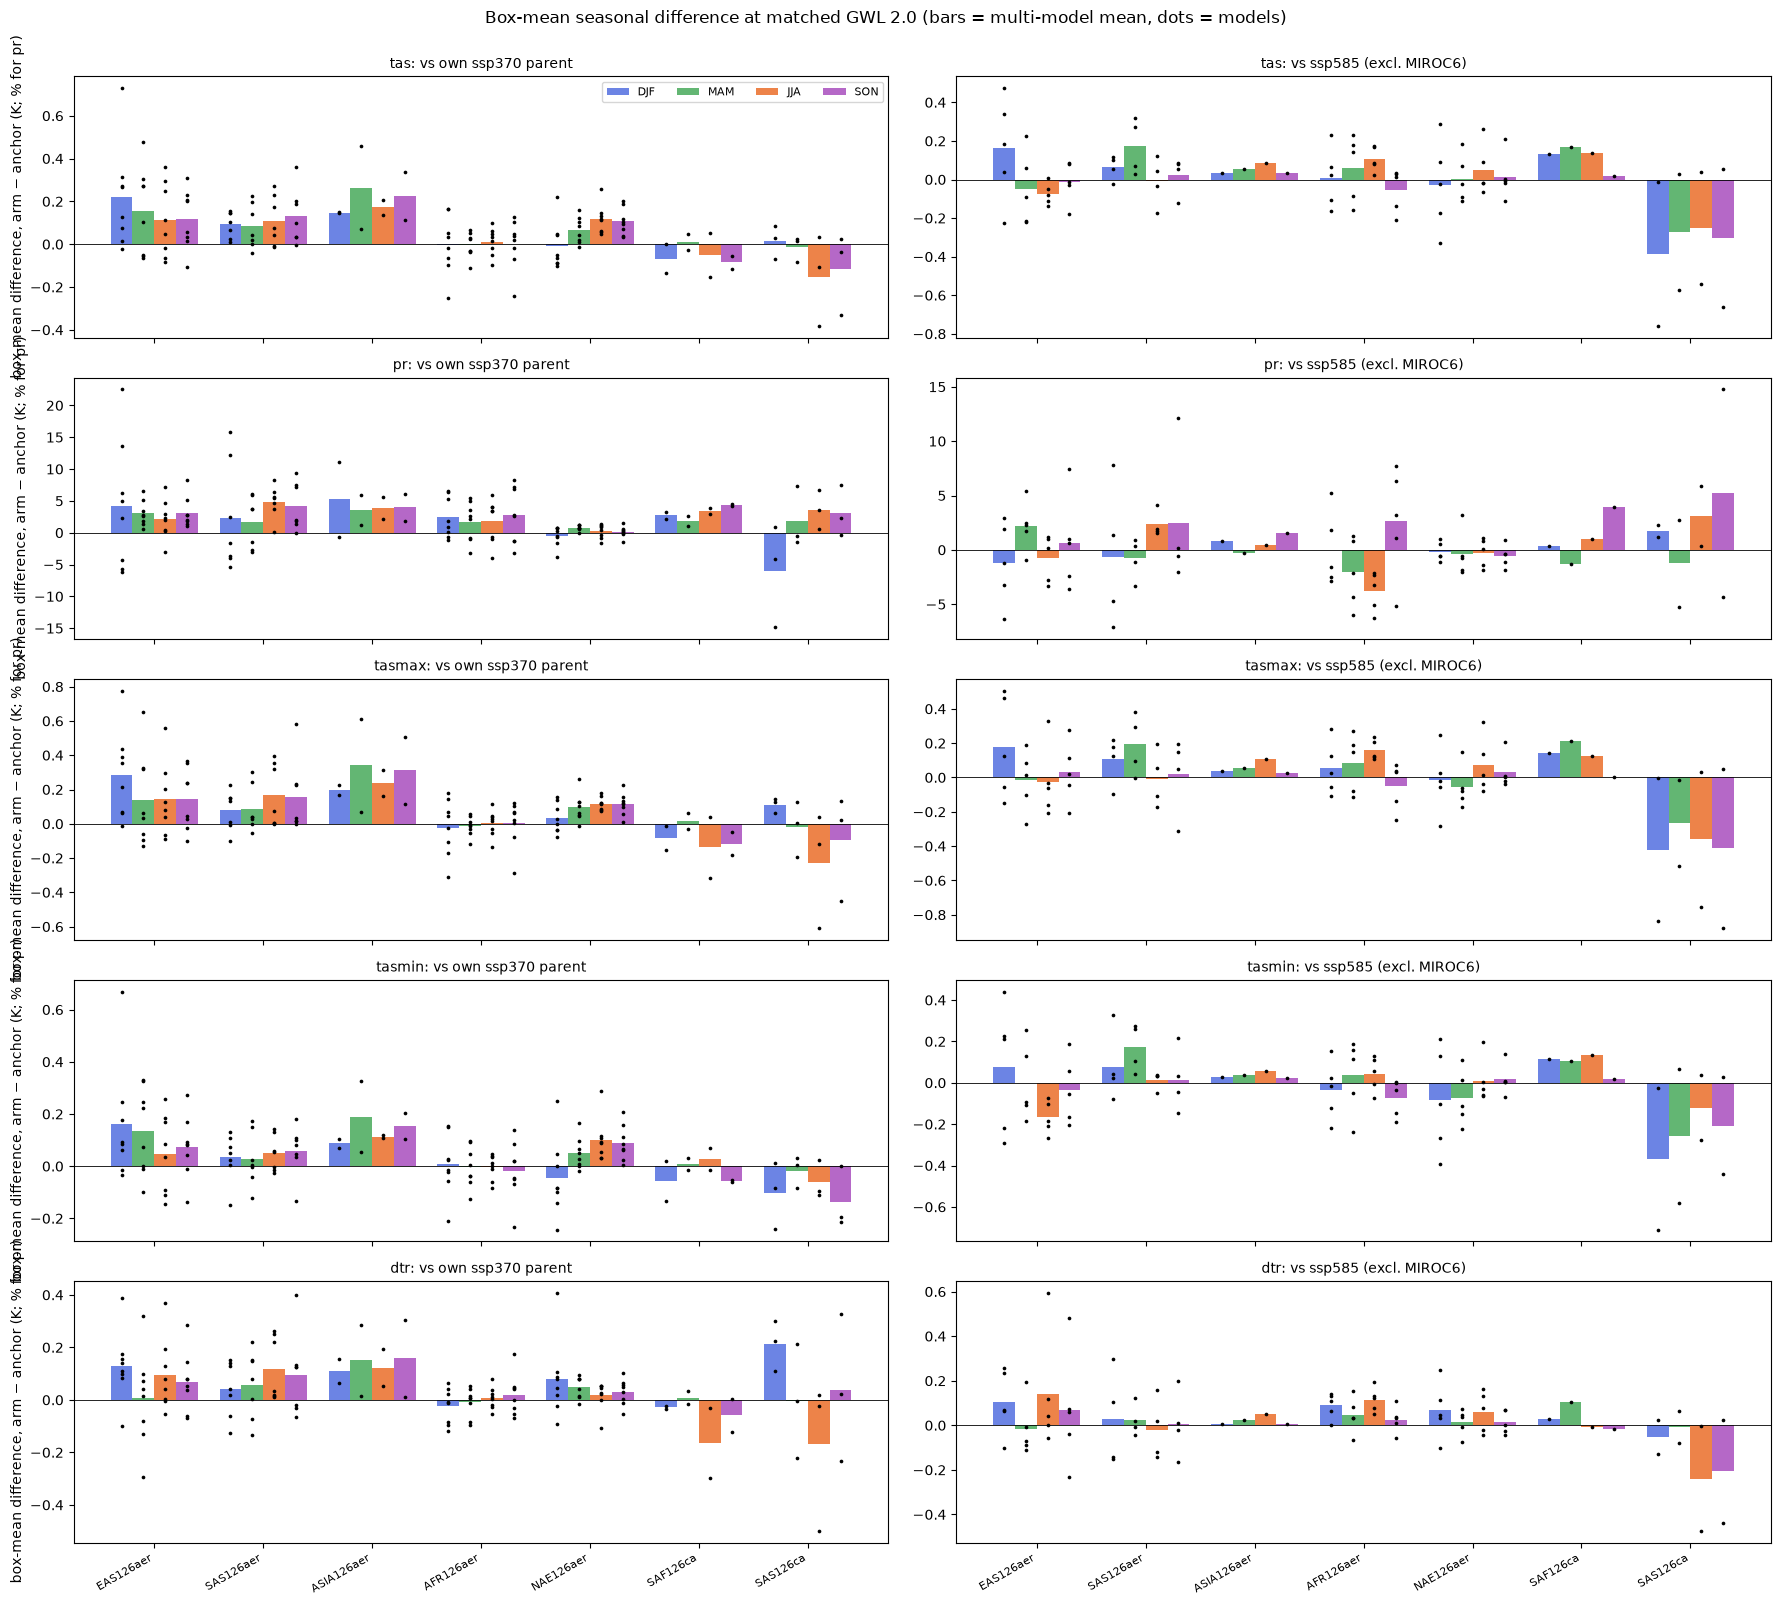

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e3_regional_arms/ks_regional_arms_seasonal_pooled.png


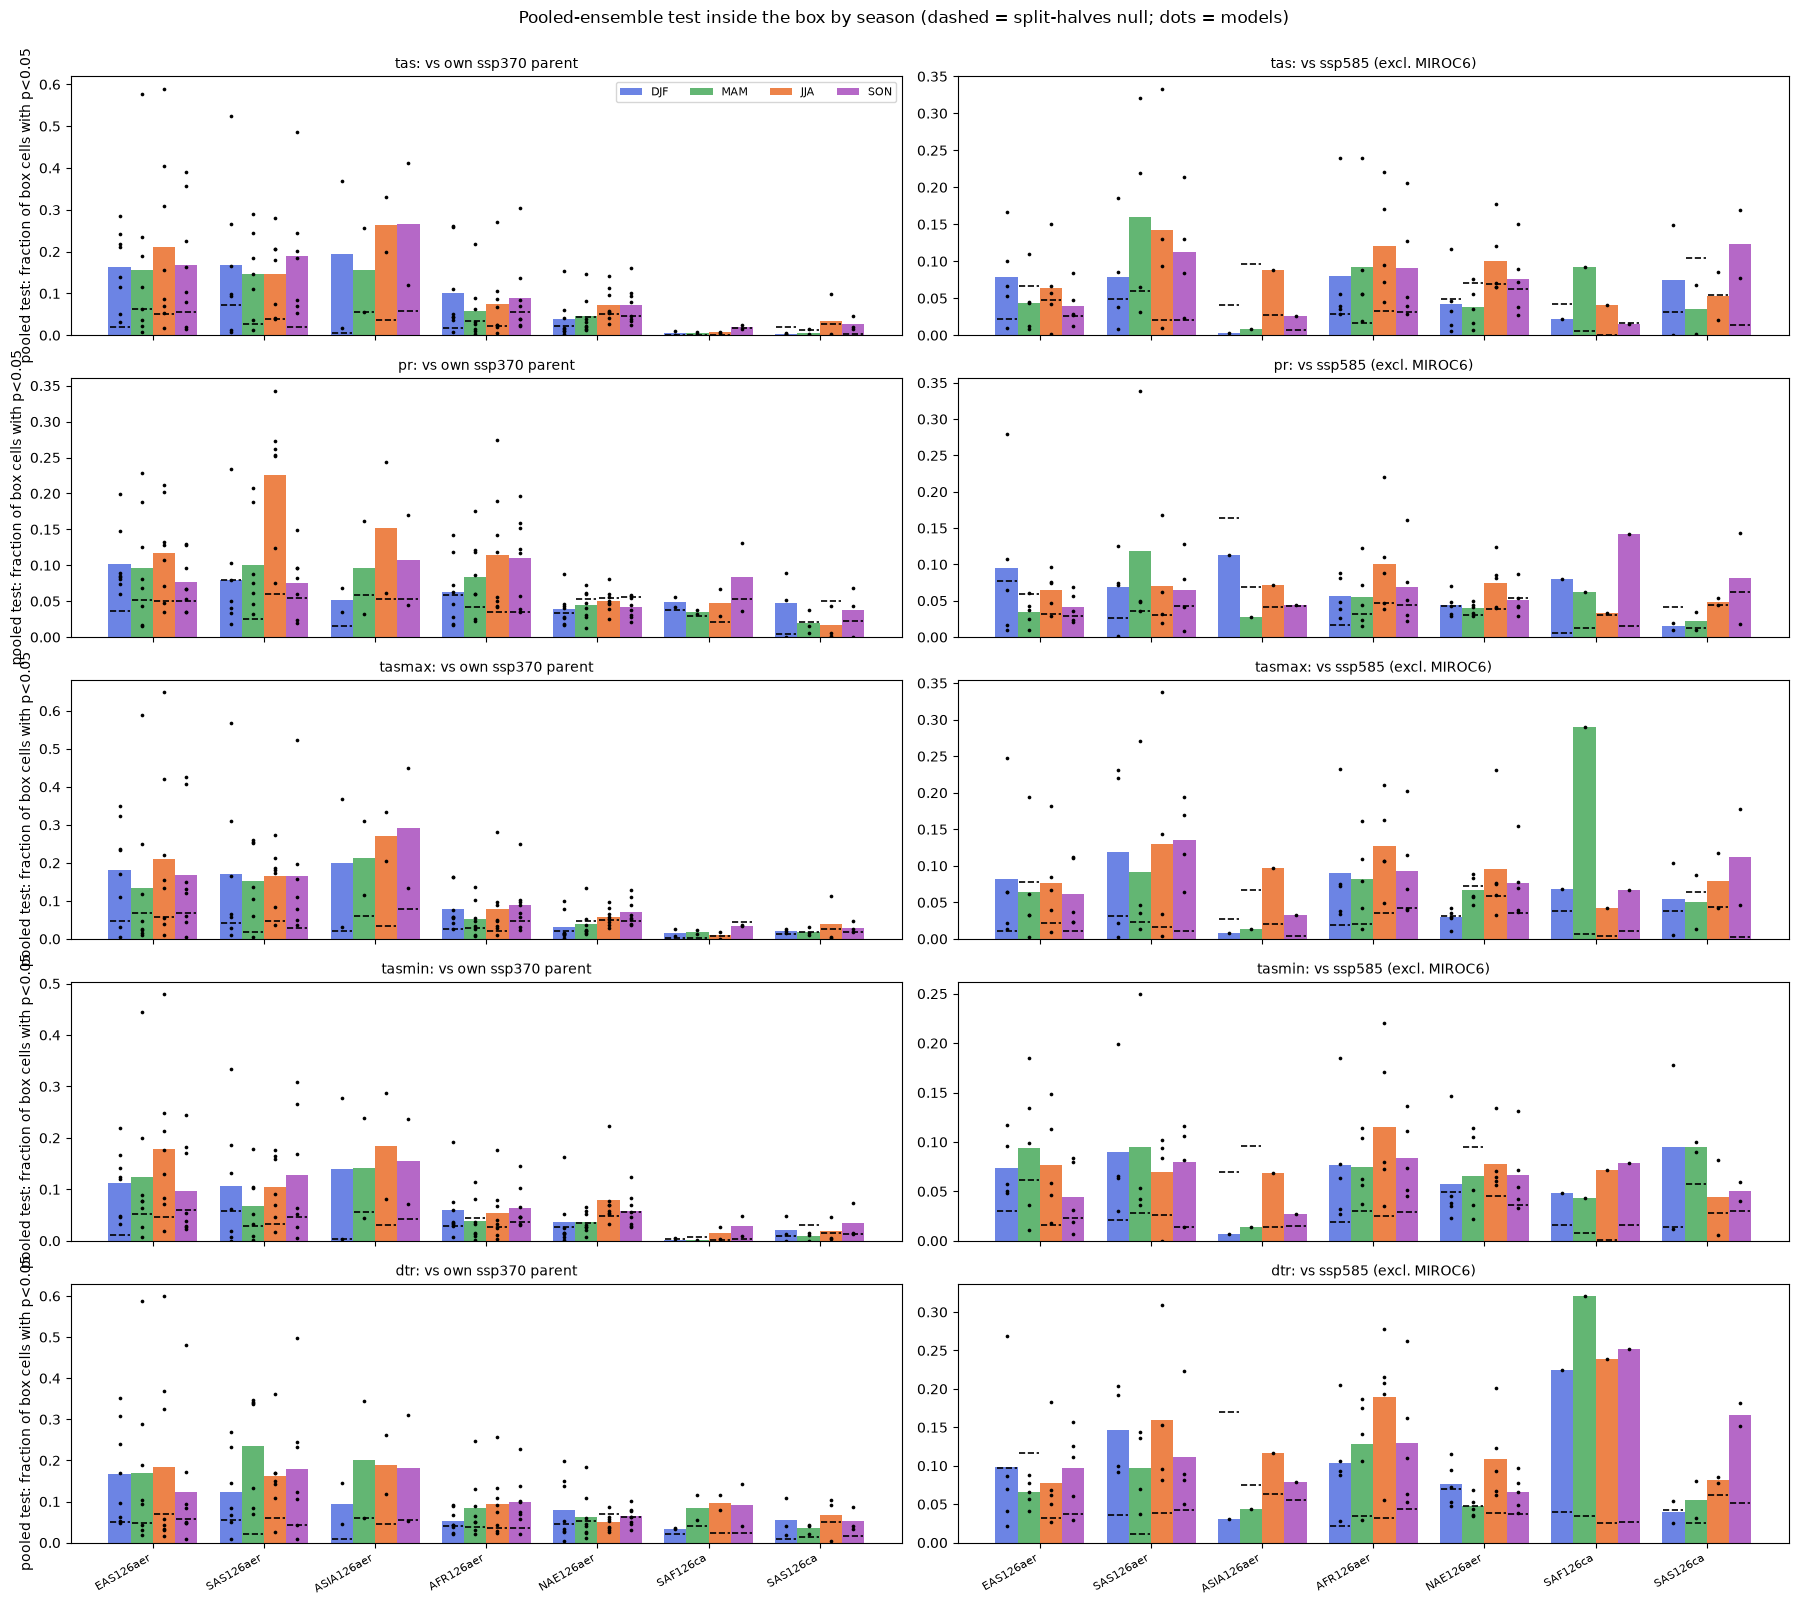

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e3_regional_arms/ks_regional_arms_seasonal_maps_tas.png


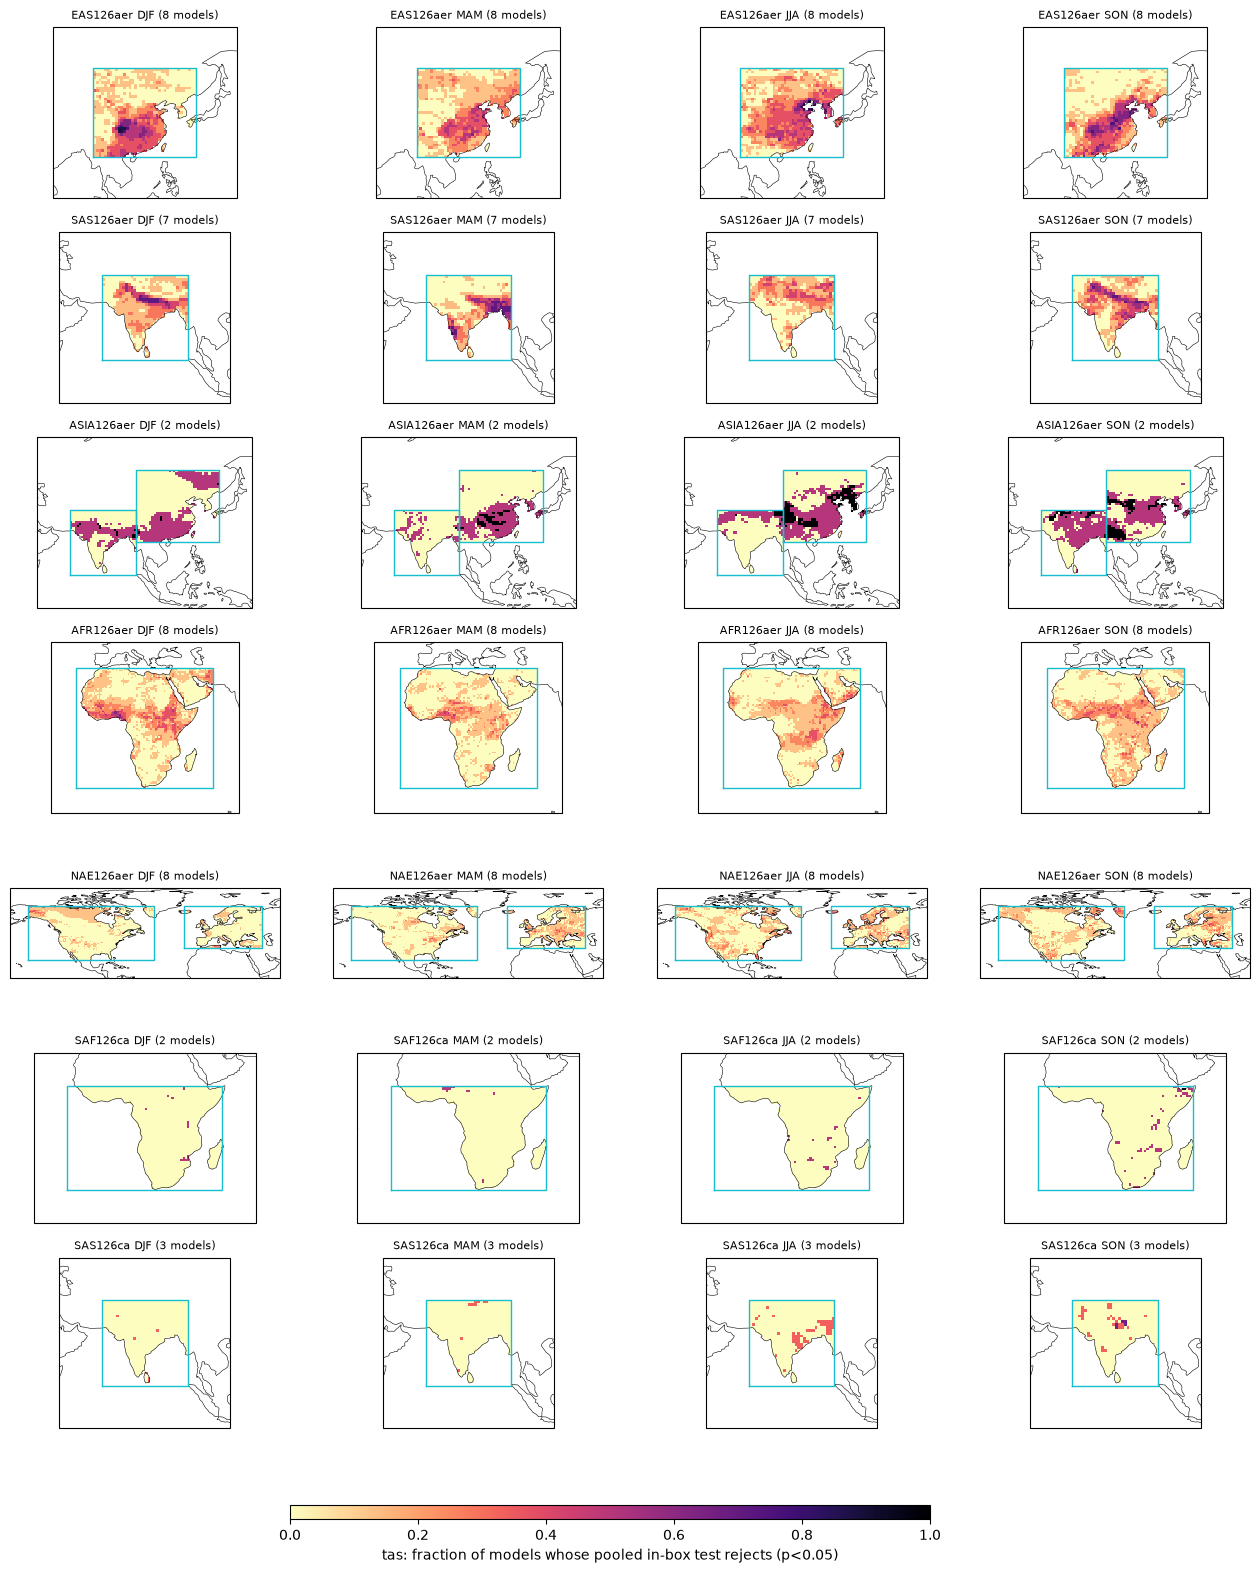

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e3_regional_arms/ks_regional_arms_seasonal_maps_pr.png


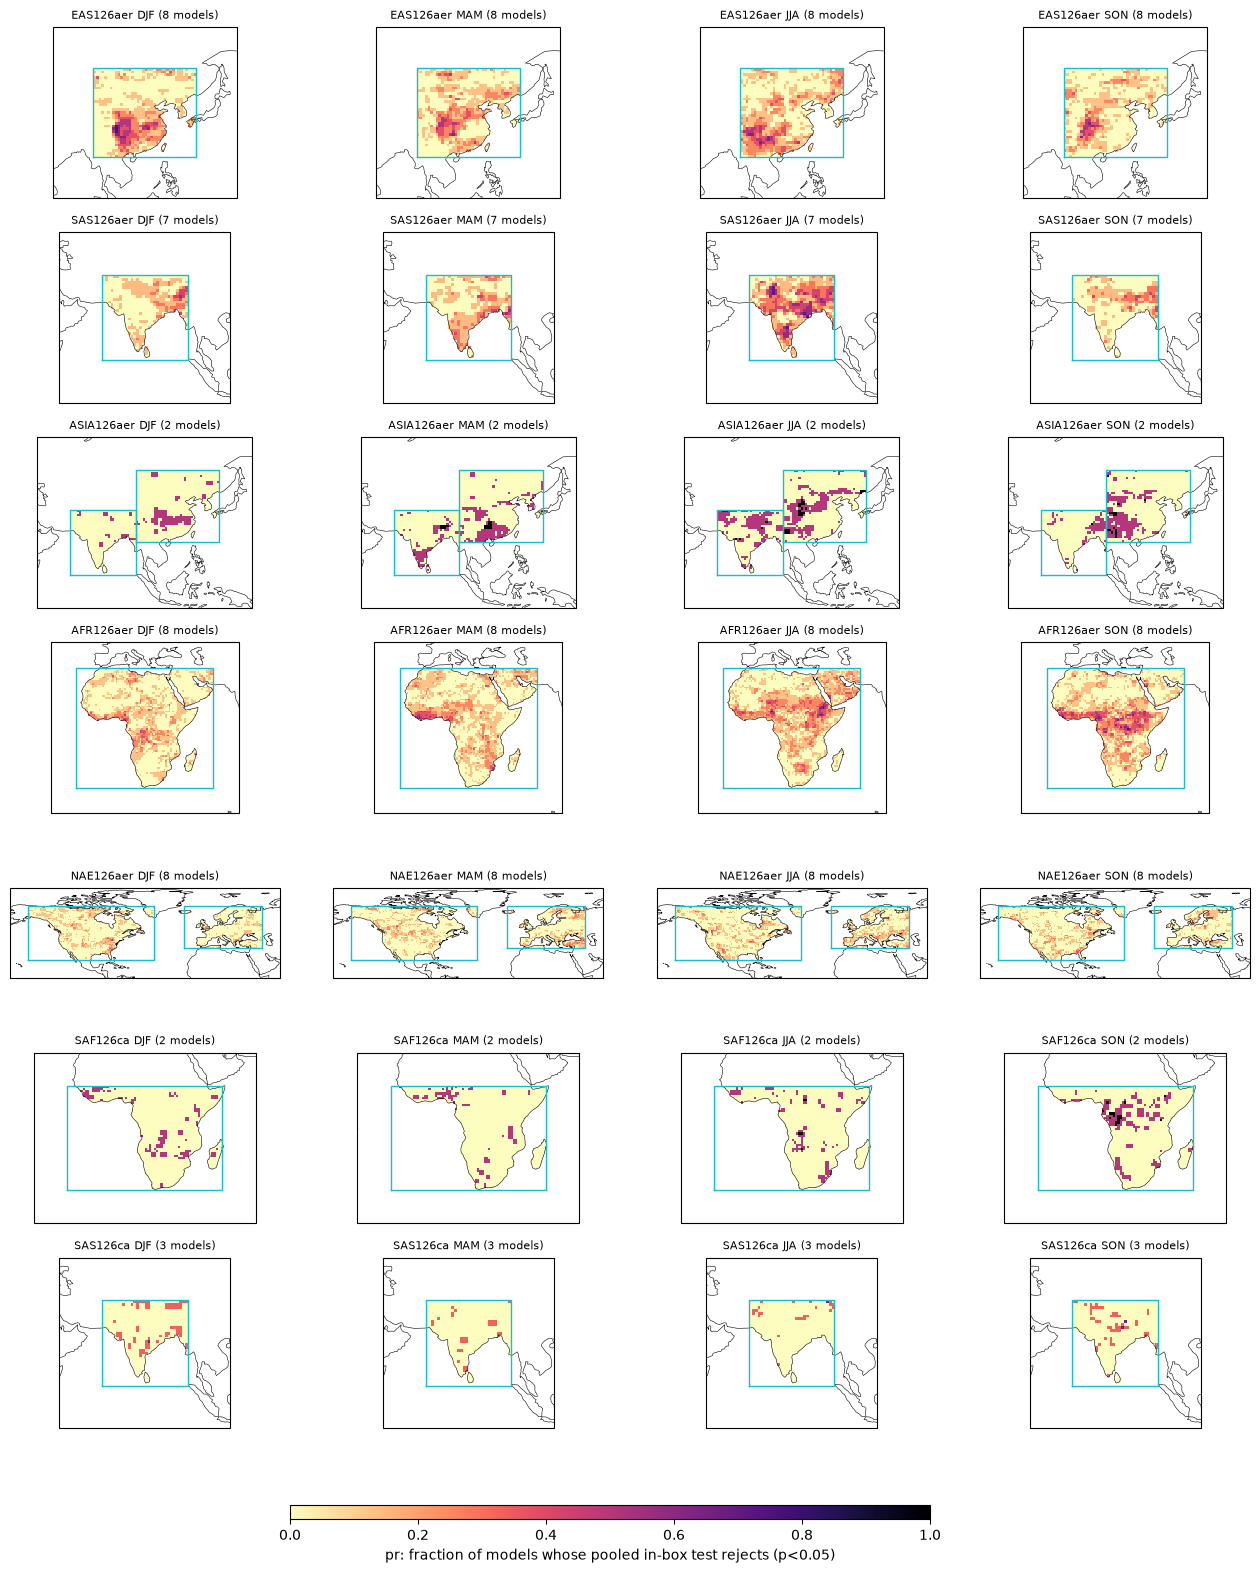

saved /burg-archive/home/mck2199/summer/summer_data/aux/../figures/e3_regional_arms/ks_regional_arms_seasonal_maps_dtr.png


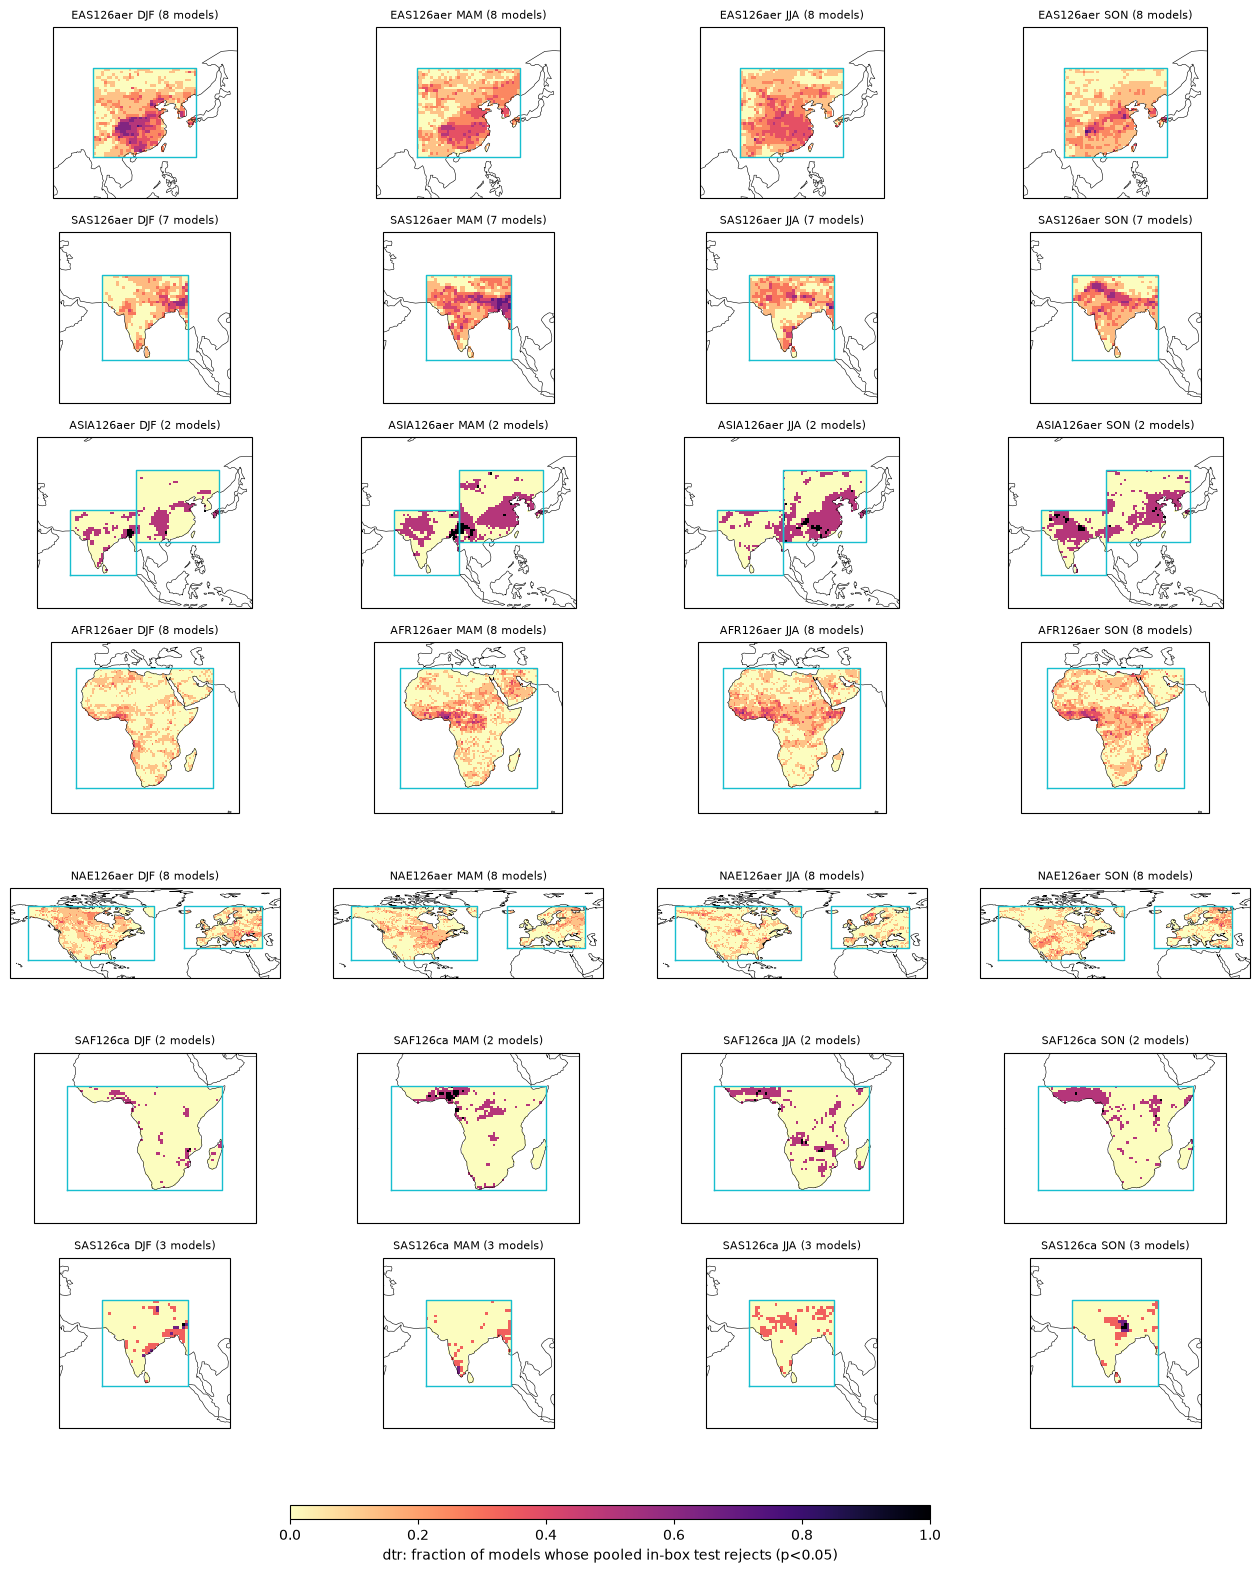

In [4]:
if ONLY_ARM or ONLY_ANCHOR:
    print('subset run: figures are produced by the FINAL pass')
else:
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    ARM_ORDER = ['eas', 'sas', 'asia', 'afr', 'nae', 'safca', 'sasca']
    LABEL = {'eas': 'EAS126aer', 'sas': 'SAS126aer', 'asia': 'ASIA126aer', 'afr': 'AFR126aer',
             'nae': 'NAE126aer', 'safca': 'SAF126ca', 'sasca': 'SAS126ca'}
    ANC_LABEL = {'370': 'vs own ssp370 parent', '585': 'vs ssp585 (excl. MIROC6)'}
    SCOL = {'DJF': '#3b5bdb', 'MAM': '#2f9e44', 'JJA': '#e8590c', 'SON': '#9c36b5'}
    x = np.arange(len(ARM_ORDER)); BW = 0.2

    def grouped(col, ylabel, fn, null_col=None, dots=True, title=''):
        fig, axs = plt.subplots(len(VARS), 2, figsize=(18, 3.2 * len(VARS)), sharex=True)
        for r, var in enumerate(VARS):
            for c, anc in enumerate(['370', '585']):
                ax = axs[r, c]
                for k, s in enumerate(SEASONS):
                    off = (k - 1.5) * BW
                    for a, arm in enumerate(ARM_ORDER):
                        d = summ[(summ.anchor == anc) & (summ.arm == arm) & (summ['var'] == var) & (summ.season == s)]
                        if d.empty:
                            continue
                        ax.bar(a + off, float(d[col].iloc[0]), BW, color=SCOL[s], alpha=0.75, label=s if a == 0 else None)
                        if null_col:
                            ax.hlines(float(d[null_col].iloc[0]), a + off - 0.45 * BW, a + off + 0.45 * BW, color='k', ls='--', lw=1.2)
                        if dots:
                            dd = bym[(bym.anchor == anc) & (bym.arm == arm) & (bym['var'] == var) & (bym.season == s)]
                            ax.scatter(np.full(len(dd), a + off), dd[col], s=7, color='k', zorder=3, lw=0)
                ax.axhline(0, color='k', lw=0.6)
                ax.set_title(f'{var}: {ANC_LABEL[anc]}', fontsize=10)
                if c == 0:
                    ax.set_ylabel(ylabel)
                ax.set_xticks(x, [LABEL[a] for a in ARM_ORDER], rotation=30, ha='right', fontsize=8)
        axs[0, 0].legend(fontsize=8, ncol=4, title=None)
        fig.suptitle(title, y=1.0); fig.tight_layout()
        fig.savefig(out_dir + fn, dpi=150, bbox_inches='tight'); print('saved', out_dir + fn); plt.show()

    grouped('fdr_in_box', 'in-box FDR fraction', 'ks_regional_arms_seasonal_inbox.png', null_col='null_fdr_in_box', dots=True,
            title='In-box FDR fraction by season (dashed = seasonal same-forcing null for the box; dots = models)')
    grouped('d_box', 'box-mean difference, arm − anchor (K; % for pr)', 'ks_regional_arms_seasonal_effect.png', dots=True,
            title='Box-mean seasonal difference at matched GWL 2.0 (bars = multi-model mean, dots = models)')
    grouped('pooled_in_box', 'pooled test: fraction of box cells with p<0.05', 'ks_regional_arms_seasonal_pooled.png',
            null_col='pooled_null_in_box', dots=True, title='Pooled-ensemble test inside the box by season (dashed = split-halves null; dots = models)')

    # regional maps of the pooled test, vs ssp370: rows arms, columns seasons, extent = box ± 15 deg
    for var in ['tas', 'pr', 'dtr']:
        fig, axs = plt.subplots(len(ARM_ORDER), 4, figsize=(16, 2.6 * len(ARM_ORDER)), subplot_kw={'projection': ccrs.PlateCarree()})
        for r, arm in enumerate(ARM_ORDER):
            sets = [v for k, v in results.items() if k[:3] == ('370', arm, var)]
            (la, lb), (lo_, hi_) = BOXES[arm][0]
            for bb in BOXES[arm][1:]:
                la, lb, lo_, hi_ = min(la, bb[0][0]), max(lb, bb[0][1]), min(lo_, bb[1][0]), max(hi_, bb[1][1])
            for c, s in enumerate(SEASONS):
                ax = axs[r, c]; ax.coastlines(lw=0.4)
                ax.set_extent([lo_ - 15, hi_ + 15, max(la - 15, -89), min(lb + 15, 89)], crs=ccrs.PlateCarree())
                if sets:
                    rej = np.nanmean([(v.p_pooled.sel(season=s).values < ALPHA).astype(float) for v in sets], axis=0)
                    rej = np.where(BOX1[arm].reshape(kt.NLAT, kt.NLON), rej, np.nan)
                    im = ax.pcolormesh(kt.GRID_OUT['lon'], kt.GRID_OUT['lat'], rej, cmap='magma_r', vmin=0, vmax=1, transform=ccrs.PlateCarree())
                for (a_, b_), (c_, d_) in BOXES[arm]:
                    ax.plot([c_, d_, d_, c_, c_], [a_, a_, b_, b_, a_], color='tab:cyan', lw=1, transform=ccrs.PlateCarree())
                ax.set_title(f'{LABEL[arm]} {s} ({len(sets)} models)', fontsize=8)
        cax = fig.add_axes([0.3, 0.06, 0.4, 0.008])
        fig.colorbar(im, cax=cax, orientation='horizontal', label=f'{var}: fraction of models whose pooled in-box test rejects (p<{ALPHA})')
        fn = out_dir + f'ks_regional_arms_seasonal_maps_{var}.png'
        fig.savefig(fn, dpi=130, bbox_inches='tight'); print('saved', fn); plt.show()

## Reading the results

**Per cell and per pair, the seasons add little**: with 30 months per side the in-box FDR fractions against the own
parent stay below 0.04 for every arm, variable and season (East Asia `tasmax` in DJF, 0.036 against a null of
0.024, is the largest), as the power argument predicted. The seasonal same-forcing null is itself slightly liberal
for temperature in winter and spring (global land 0.07 in DJF/MAM against 0.06 in JJA) and conservative for
precipitation (0.04), so in-box numbers must be read against the null for that box and season.

**With the ensemble pooled, the seasonal fingerprint is clear and physically sensible** (fraction of box cells
rejecting, multi-model mean, against the split-halves null of 0.02–0.07):

- **East Asia**: temperature 0.16–0.21 in every season with JJA highest (0.21), `tasmax` 0.18–0.21, the diurnal
  range 0.17–0.18 from DJF to JJA, precipitation 0.10–0.12. The maps put the signal over the North China Plain and
  the Sichuan–Yangtze region in all seasons. Box-mean warming is largest in winter (+0.22 K, `tasmax` +0.29 K in DJF)
  and precipitation +4 % in DJF.
- **South Asia**: precipitation 0.23 in JJA against a null of 0.06 — the monsoon-season signal, +4.9 % in JJA and
  +4.2 % in SON — while the temperature signal sits in the dry seasons: the diurnal range 0.24 in MAM, `tas` 0.19
  in SON, and the maps place it along the Indo-Gangetic plain in DJF and SON, the haze season.
- **Combined Asia** (2 models): `tas` and `tasmax` 0.27–0.29 in JJA and SON over eastern China; +0.26 K in MAM.
- **Africa**: weak (`tas` 0.10 in DJF over the Sahel; precipitation and diurnal range 0.09–0.11 against 0.04–0.06),
  with box-mean changes near zero.
- **North America/Europe**: nothing in any season (0.03–0.08 against 0.02–0.07; +0.12 K in JJA at most).
- **Carbonaceous-only arms**: no temperature signal (0.005–0.04); a weak diurnal-range signal for sub-Saharan
  Africa (0.09–0.10 in MAM–SON) and precipitation in SON (0.08). Their box-mean temperature changes are negative
  (SAF −0.05 to −0.08 K, SAS-ca −0.15 K in JJA with `tasmax` −0.23 K), the sign expected from removing absorbing
  aerosol, but on 2–3 models.

**Against ssp585** the seasonal in-box FDR is ≤ 0.02 except the diurnal range (AFR 0.02–0.05, SAF-ca 0.06–0.12 in
one model), the same cross-archive diurnal-range difference seen in the full-window analysis.

So the aerosol fingerprint has a season: summer monsoon rain over South Asia, winter haze-season temperature along
the Indo-Gangetic plain, year-round daytime warming over eastern China. At the scale of the ensemble it is
unambiguous; at the scale of one pair of 10-year windows it is below the test's resolution in every season.